# Netflix Movies and TV Shows – Exploratory Data Analysis (EDA)

**CodeAlpha Data Analytics Internship – Task 2**

**Objective:** Explore the Netflix Movies and TV Shows dataset to understand its structure, find data quality issues, discover trends and patterns, detect anomalies, and communicate insights with statistics and charts.

**Dataset:** [Netflix Movies and TV Shows (Kaggle, by Shivam Bansal)](https://www.kaggle.com/datasets/shivamb/netflix-shows) – file `netflix_titles.csv`

**Sections**
1. Import libraries
2. Load and inspect the dataset
3. Identify data quality issues
4. Clean the data
5. Ask meaningful questions
6. Exploratory analysis
7. Visualizations
8. Key findings
9. Conclusion

> **Before running:** download `netflix_titles.csv` from Kaggle and place it in the same folder as this notebook (or upload it to Google Colab). If your file is somewhere else, change `DATA_PATH` in Step 2.

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make charts look clean and show all columns when printing tables
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load and Inspect the Dataset

In [2]:
from pathlib import Path

# Look for the CSV next to this notebook, then in the working folder, then Colab's /content.
candidates = []
try:
    candidates.append(Path(__vsc_ipynb_file__).resolve().parent / "netflix_titles.csv")
except NameError:
    pass
candidates.extend([
    Path.cwd() / "netflix_titles.csv",
    Path("/content/netflix_titles.csv"),
])
DATA_PATH = next((p for p in candidates if p.exists()), Path.cwd() / "netflix_titles.csv")

try:
    df_raw = pd.read_csv(DATA_PATH)   # df_raw is kept untouched as the original data
except FileNotFoundError:
    raise FileNotFoundError(
        f"Could not find '{DATA_PATH}'. Download netflix_titles.csv from Kaggle "
        "(https://www.kaggle.com/datasets/shivamb/netflix-shows), place it next to this "
        "notebook (or upload it to Colab), and update DATA_PATH if needed."
    )

print(f"Dataset loaded from: {DATA_PATH}")

Dataset loaded from: C:\Users\ASUS\Desktop\data analytics project1\netflix_titles.csv


In [3]:
# First five and last five rows
print("First 5 rows:")
display(df_raw.head())

print("Last 5 rows:")
display(df_raw.tail())

First 5 rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, Rodolfo Val...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi & Fantasy",In a future where the elite inhabit an island paradise f...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, Azalia Ort...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies","After a devastating earthquake hits Mexico City, trapped..."
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence Koh, Tommy...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow soldiers ..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly, Christop...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi & Fantasy","In a postapocalyptic world, rag-doll robots hide in fear..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aaron Yoo, Li...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-counting exper...


Last 5 rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
7782,s7783,Movie,Zozo,Josef Fares,"Imad Creidi, Antoinette Turk, Elias Gergi, Carmen Lebbos...","Sweden, Czech Republic, United Kingdom, Denmark, Netherl...","October 19, 2020",2005,TV-MA,99 min,"Dramas, International Movies","When Lebanon's Civil War deprives Zozo of his family, he..."
7783,s7784,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanana, Manish ...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a tycoon's dys...
7784,s7785,Movie,Zulu Man in Japan,NaN,Nasty C,NaN,"September 25, 2020",2019,TV-MA,44 min,"Documentaries, International Movies, Music & Musicals","In this documentary, South African rapper Nasty C hits t..."
7785,s7786,TV Show,Zumbo's Just Desserts,NaN,"Adriano Zumbo, Rachel Khoo",Australia,"October 31, 2020",2019,TV-PG,1 Season,"International TV Shows, Reality TV",Dessert wizard Adriano Zumbo looks for the next “Willy W...
7786,s7787,Movie,ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS,Sam Dunn,NaN,"United Kingdom, Canada, United States","March 1, 2020",2019,TV-MA,90 min,"Documentaries, Music & Musicals",This documentary delves into the mystique behind the blu...


In [4]:
# Size of the dataset, column names and data types
rows, cols = df_raw.shape
print(f"Number of rows   : {rows:,}")
print(f"Number of columns: {cols}")

print("\nColumn names:")
print(list(df_raw.columns))

print("\nData types:")
print(df_raw.dtypes)

Number of rows   : 7,787
Number of columns: 12

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types:
show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


In [5]:
# Overview: non-null counts and memory usage
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       7787 non-null   str  
 1   type          7787 non-null   str  
 2   title         7787 non-null   str  
 3   director      5398 non-null   str  
 4   cast          7069 non-null   str  
 5   country       7280 non-null   str  
 6   date_added    7777 non-null   str  
 7   release_year  7787 non-null   int64
 8   rating        7780 non-null   str  
 9   duration      7787 non-null   str  
 10  listed_in     7787 non-null   str  
 11  description   7787 non-null   str  
dtypes: int64(1), str(11)
memory usage: 730.2 KB


In [6]:
# Summary statistics
print("Numerical columns:")
display(df_raw.describe())

print("Text (non-numerical) columns:")
display(df_raw.select_dtypes(exclude="number").describe())

Numerical columns:


,release_year
count,7787.000000
mean,2013.932580
std,8.757395
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2018.000000
max,2021.000000


Text (non-numerical) columns:


,show_id,type,title,director,cast,country,date_added,rating,duration,listed_in,description
count,7787,7787,7787,5398,7069,7280,7777,7780,7787,7787,7787
unique,7787,2,7787,4049,6831,681,1565,14,216,492,7769
top,s1,Movie,3%,"Raúl Campos, Jan Suter",David Attenborough,United States,"January 1, 2020",TV-MA,1 Season,Documentaries,Multiple women report their husbands as missing but when...
freq,1,5377,1,18,18,2555,118,2863,1608,334,3


**What to notice:** `release_year` is the only numerical column, so `describe()` mainly summarises that one. Most columns are text. `date_added` and `duration` are stored as text and will need conversion later. The text summary shows how many unique values each column has and its most frequent value.

## Step 3: Identify Data Quality Issues

In [7]:
# 3.1 Missing values in every column
missing_count = df_raw.isnull().sum()
missing_pct = (missing_count / len(df_raw) * 100).round(2)

missing_table = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_pct
}).sort_values("missing_count", ascending=False)

display(missing_table)

,missing_count,missing_percent
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09
title,0,0.00
show_id,0,0.00
type,0,0.00
release_year,0,0.00
duration,0,0.00


In [8]:
# 3.2 Duplicate records
issues = {}   # we collect every issue here so we can summarise it later

issues["full_duplicate_rows"] = int(df_raw.duplicated().sum())
issues["duplicate_show_id"] = int(df_raw["show_id"].duplicated().sum())
issues["duplicate_title_type_year"] = int(
    df_raw.duplicated(subset=["title", "type", "release_year"]).sum()
)

print(f"Fully identical rows                 : {issues['full_duplicate_rows']}")
print(f"Repeated show_id values              : {issues['duplicate_show_id']}")
print(f"Repeated (title + type + release_year): {issues['duplicate_title_type_year']}")

Fully identical rows                 : 0


Repeated show_id values              : 0
Repeated (title + type + release_year): 0


In [9]:
# 3.3 Invalid, inconsistent or unusual values
print("Release year range:", df_raw["release_year"].min(), "to", df_raw["release_year"].max())
print("Unique values in 'type':", df_raw["type"].dropna().unique().tolist())

# (a) Rating column should contain ratings like 'PG-13', not durations like '74 min'
rating_text = df_raw["rating"].dropna().astype(str).str.strip()
rating_has_duration = rating_text.str.contains("min", case=False)
issues["rating_contains_duration"] = int(rating_has_duration.sum())
print(f"\nRows where 'rating' looks like a duration: {issues['rating_contains_duration']}")
if rating_has_duration.any():
    print(rating_text[rating_has_duration].value_counts())

# (b) Movies should have minutes and TV Shows should have seasons in 'duration'
has_duration = df_raw["duration"].notna()
movie_bad = (df_raw["type"] == "Movie") & has_duration & ~df_raw["duration"].str.contains("min", na=False)
tv_bad = (df_raw["type"] == "TV Show") & has_duration & ~df_raw["duration"].str.contains("Season", na=False)
issues["duration_type_mismatch"] = int((movie_bad | tv_bad).sum())
print(f"Rows where 'duration' does not match 'type': {issues['duration_type_mismatch']}")

# (c) Extra leading/trailing spaces in text cells
space_cells = 0
for col in df_raw.select_dtypes(exclude="number").columns:
    s = df_raw[col].dropna().astype(str)
    space_cells += int((s != s.str.strip()).sum())
issues["text_cells_with_extra_spaces"] = space_cells
print(f"Text cells with extra leading/trailing spaces: {space_cells}")

# (d) date_added stored as text - can every value be converted to a date?
date_text = df_raw["date_added"].dropna().str.strip()
parsed_dates = pd.to_datetime(date_text, errors="coerce", format="mixed")
issues["unparseable_dates"] = int(parsed_dates.isnull().sum())
print(f"date_added values that cannot be converted to a date: {issues['unparseable_dates']}")

# (e) Overall missing values
issues["columns_with_missing_values"] = int((missing_count > 0).sum())
issues["total_missing_cells"] = int(missing_count.sum())
print(f"\nColumns with missing values: {issues['columns_with_missing_values']}")
print(f"Total missing cells         : {issues['total_missing_cells']:,}")

Release year range: 1925 to 2021
Unique values in 'type': ['TV Show', 'Movie']

Rows where 'rating' looks like a duration: 0


Rows where 'duration' does not match 'type': 0
Text cells with extra leading/trailing spaces: 89


date_added values that cannot be converted to a date: 0

Columns with missing values: 5
Total missing cells         : 3,631


**Explanation of the issues checked**
- **Missing values** are the most common problem in this dataset. Columns such as `director`, `cast` and `country` are descriptive, so a missing value usually means "not recorded", not an error.
- **Duplicates:** we checked identical rows, repeated `show_id` values, and repeated title/type/year combinations. Only *fully identical* rows are safe to remove automatically.
- **Inconsistent values:** if the `rating` column contains durations such as "74 min", the values were probably entered in the wrong column.
- **Text formats:** `date_added` and `duration` are text and must be converted before they can be analysed.

## Step 4: Clean the Data
We work on a **copy** (`df`) so the original (`df_raw`) stays unchanged.

In [10]:
# 4.1 Create a working copy
df = df_raw.copy()
print("Working copy created. Shape:", df.shape)

Working copy created. Shape: (7787, 12)


**4.2 Remove extra spaces from text columns.** Spaces at the start or end of a value (for example `" United States"`) make the same value look different when grouping or counting.

In [11]:
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    df[col] = df[col].str.strip()

print("Extra spaces removed from", len(text_cols), "text columns.")

Extra spaces removed from 11 text columns.


**4.3 Remove duplicate records (only if justified).** We only remove rows that are *completely identical* in every column, because those are genuine repeats. Rows that only share a title are **not** removed – two different titles can legitimately share a name.

In [12]:
rows_before = len(df)
df = df.drop_duplicates()
rows_removed = rows_before - len(df)

print(f"Rows before: {rows_before:,} | Rows after: {len(df):,} | Duplicate rows removed: {rows_removed}")

Rows before: 7,787 | Rows after: 7,787 | Duplicate rows removed: 0


**4.4 Fix ratings that contain durations.** If a `rating` value looks like a duration (e.g. "74 min") and the `duration` cell is empty, we move the value to `duration`. The wrong rating value is then treated as missing. This keeps useful data instead of deleting the row.

In [13]:
rating_is_duration = df["rating"].str.contains("min", case=False, na=False)
move_mask = rating_is_duration & df["duration"].isnull()

df.loc[move_mask, "duration"] = df.loc[move_mask, "rating"]   # keep the information
df.loc[rating_is_duration, "rating"] = np.nan                  # rating itself is unknown

print("Rating values that looked like durations:", int(rating_is_duration.sum()))
print("Of these, moved into the empty 'duration' column:", int(move_mask.sum()))

Rating values that looked like durations: 0
Of these, moved into the empty 'duration' column: 0


**4.5 Handle missing values.**
- `director`, `cast`, `country` and `rating` are text categories. Instead of deleting those rows (which would lose many useful titles), we fill the gaps with the label **"Unknown"**. These labels are excluded from country rankings later.
- `date_added` and `duration` are **not** guessed. Inventing a date or a length would create false data, so these stay missing.

In [14]:
for col in ["director", "cast", "country", "rating"]:
    df[col] = df[col].fillna("Unknown")

print("Filled missing values with 'Unknown' in: director, cast, country, rating")

Filled missing values with 'Unknown' in: director, cast, country, rating


**4.6 Convert data types.**
- `date_added` (text) → a real date using `pd.to_datetime`. Values that cannot be converted become `NaT` (missing) instead of causing an error.
- We also create helper columns: `year_added`, `decade`, and split `duration` into a number (`duration_value`) and a unit (`duration_unit`: minutes for Movies, seasons for TV Shows).

In [15]:
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce", format="mixed")
df["year_added"] = df["date_added"].dt.year

df["decade"] = (df["release_year"] // 10) * 10

df["duration_value"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")
df["duration_unit"] = df["duration"].str.extract(r"\d+\s*([A-Za-z]+)")[0]

print("Data types after conversion:")
print(df[["date_added", "year_added", "decade", "duration_value", "duration_unit"]].dtypes)

Data types after conversion:


date_added        datetime64[us]
year_added               float64
decade                     int64
duration_value             int64
duration_unit                str
dtype: object


**4.7 Recheck missing values and duplicates after cleaning.**

In [16]:
missing_after = pd.DataFrame({
    "missing_before": df_raw.isnull().sum(),
    "missing_after": df.isnull().sum()
}).fillna(0).astype(int)
missing_after = missing_after.sort_values("missing_after", ascending=False)

display(missing_after)
print("Duplicate rows remaining:", int(df.duplicated().sum()))
print("Final shape:", df.shape)

,missing_before,missing_after
date_added,10,10
year_added,0,10
country,507,0
cast,718,0
description,0,0
director,2389,0
duration,0,0
decade,0,0
duration_unit,0,0
duration_value,0,0


Duplicate rows remaining: 0
Final shape: (7787, 16)


## Step 5: Ask Meaningful Questions
Each answer below is calculated directly from the cleaned dataset.

### Q1. How many Movies and TV Shows are present?

In [17]:
type_counts = df["type"].value_counts()
type_pct = (df["type"].value_counts(normalize=True) * 100).round(2)

display(pd.DataFrame({"count": type_counts, "percent": type_pct}))

,count,percent
type,,
Movie,5377,69.05
TV Show,2410,30.95


### Q2. Which release years have the highest number of titles?

In [18]:
top_years = df["release_year"].value_counts().head(10)
display(top_years.rename("number_of_titles").to_frame())

,number_of_titles
release_year,
2018,1121
2017,1012
2019,996
2016,882
2020,868
2015,541
2014,334
2013,267
2012,219


### Q3. Which countries contribute the most titles?
A title can list several countries (for example `"United States, India"`), so we split the text and count the title once for **each** listed country. "Unknown" is excluded.

In [19]:
country_list = df["country"].str.split(",").explode().str.strip()
country_list = country_list[(country_list != "") & (country_list != "Unknown")]

top_countries = country_list.value_counts().head(10)
display(top_countries.rename("number_of_titles").to_frame())
print("Titles with a known country:", int((df["country"] != "Unknown").sum()), "of", len(df))

,number_of_titles
country,
United States,3297
India,990
United Kingdom,723
Canada,412
France,349
Japan,287
Spain,215
South Korea,212
Germany,199


Titles with a known country: 7280 of 7787


### Q4. Which genres appear most frequently?
The `listed_in` column holds several genres per title separated by commas, so we split it and count each genre.

In [20]:
genre_list = df["listed_in"].dropna().str.split(",").explode().str.strip()
genre_list = genre_list[genre_list != ""]

top_genres = genre_list.value_counts().head(10)
display(top_genres.rename("number_of_titles").to_frame())

,number_of_titles
listed_in,
International Movies,2437
Dramas,2106
Comedies,1471
International TV Shows,1199
Documentaries,786
Action & Adventure,721
TV Dramas,704
Independent Movies,673
Children & Family Movies,532


### Q5. Which content ratings are most common?

In [21]:
rating_counts = df["rating"].value_counts()
display(rating_counts.rename("number_of_titles").to_frame())

,number_of_titles
rating,
TV-MA,2863
TV-14,1931
TV-PG,806
R,665
PG-13,386
TV-Y,280
TV-Y7,271
PG,247
TV-G,194


### Q6. How has the distribution of content changed over time?

In [22]:
# Titles per release year, split by type
year_type = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)
year_type["All titles"] = year_type.sum(axis=1)

# Titles per release decade
decade_counts = df["decade"].value_counts().sort_index()
print("Titles by release decade:")
display(decade_counts.rename("number_of_titles").to_frame())

# Titles per year they were added to Netflix
added_per_year = df["year_added"].dropna().astype(int).value_counts().sort_index()
print("Titles by year added to Netflix:")
display(added_per_year.rename("number_of_titles").to_frame())

peak_year = int(year_type["All titles"].idxmax())
print(f"Release year with the most titles: {peak_year} ({int(year_type['All titles'].max()):,} titles)")

Titles by release decade:


,number_of_titles
decade,
1920,1
1940,14
1950,11
1960,25
1970,67
1980,106
1990,225
2000,728
2010,5711


Titles by year added to Netflix:


,number_of_titles
year_added,
2008,2
2009,2
2010,1
2011,13
2012,3
2013,11
2014,25
2015,88
2016,443


Release year with the most titles: 2018 (1,121 titles)


### Q7. What unusual values or data quality issues were identified?

In [23]:
print("Issues found in the ORIGINAL data (Step 3):")
for name, value in issues.items():
    print(f"  - {name.replace('_', ' ')}: {value:,}")

print("\nColumns with the most missing values (original data):")
display(missing_table[missing_table["missing_count"] > 0])

Issues found in the ORIGINAL data (Step 3):
  - full duplicate rows: 0
  - duplicate show id: 0
  - duplicate title type year: 0
  - rating contains duration: 0
  - duration type mismatch: 0
  - text cells with extra spaces: 89
  - unparseable dates: 0
  - columns with missing values: 5
  - total missing cells: 3,631

Columns with the most missing values (original data):


,missing_count,missing_percent
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09


## Step 6: Perform Exploratory Analysis

### 6.1 Numerical variables
`release_year` is the main numerical column. `duration_value` is numerical too, but it means **minutes** for Movies and **seasons** for TV Shows, so we analyse them separately.

In [24]:
print("release_year summary:")
display(df["release_year"].describe())

movies = df[df["type"] == "Movie"].copy()
tv_shows = df[df["type"] == "TV Show"].copy()

movie_minutes = movies["duration_value"].dropna()
tv_seasons = tv_shows["duration_value"].dropna()

print("Movie duration (minutes):")
display(movie_minutes.describe())

print("TV Show duration (number of seasons):")
display(tv_seasons.describe())

print("TV Shows by number of seasons:")
display(tv_seasons.astype(int).value_counts().sort_index().rename("number_of_shows").to_frame())

release_year summary:


count    7787.000000
mean     2013.932580
std         8.757395
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2018.000000
max      2021.000000
Name: release_year, dtype: float64

Movie duration (minutes):


count    5377.000000
mean       99.307978
std        28.530881
min         3.000000
25%        86.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64

TV Show duration (number of seasons):


count    2410.000000
mean        1.775934
std         1.596359
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        16.000000
Name: duration_value, dtype: float64

TV Shows by number of seasons:


,number_of_shows
duration_value,
1,1608
2,382
3,184
4,87
5,58
6,30
7,19
8,18
9,8


In [25]:
# Simple readable interpretation, generated from the numbers above
print("Interpretation:")
print(f"- Titles were released between {int(df['release_year'].min())} and {int(df['release_year'].max())}; "
      f"the median release year is {int(df['release_year'].median())}.")
if len(movie_minutes) > 0:
    print(f"- Movies have a median length of {movie_minutes.median():.0f} minutes "
          f"(mean {movie_minutes.mean():.1f}).")
if len(tv_seasons) > 0:
    one_season_pct = (tv_seasons == 1).mean() * 100
    print(f"- {one_season_pct:.1f}% of TV Shows have only 1 season; the maximum is {int(tv_seasons.max())} seasons.")

Interpretation:
- Titles were released between 1925 and 2021; the median release year is 2017.
- Movies have a median length of 98 minutes (mean 99.3).
- 66.7% of TV Shows have only 1 season; the maximum is 16 seasons.


### 6.2 Categorical variables

In [26]:
for col in ["type", "rating"]:
    print(f"Share of titles by {col} (%):")
    display((df[col].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame().head(8))

print("Number of different countries listed:", country_list.nunique())
print("Number of different genres listed   :", genre_list.nunique())
print("Titles with an Unknown director     :", int((df["director"] == "Unknown").sum()))
print("Titles with an Unknown cast         :", int((df["cast"] == "Unknown").sum()))

Share of titles by type (%):


,percent
type,
Movie,69.05
TV Show,30.95


Share of titles by rating (%):


,percent
rating,
TV-MA,36.77
TV-14,24.80
TV-PG,10.35
R,8.54
PG-13,4.96
TV-Y,3.60
TV-Y7,3.48
PG,3.17


Number of different countries listed: 117
Number of different genres listed   : 42
Titles with an Unknown director     : 2389
Titles with an Unknown cast         : 718


### 6.3 Relationships between variables
We look at (a) how ratings differ between Movies and TV Shows, (b) whether movie length changed with release decade, and (c) the gap between a title's release year and the year it was added to Netflix.

In [27]:
# (a) Rating mix by type (percent within each type), for the 5 most common ratings
top5_ratings = df["rating"].value_counts().head(5).index
rating_by_type = (pd.crosstab(df["type"], df["rating"], normalize="index") * 100).round(1)
print("Rating mix by type (% of each type):")
display(rating_by_type[top5_ratings])

# (b) Movie length by release decade
print("Movie length (minutes) by release decade:")
display(movies.groupby("decade")["duration_value"].agg(["count", "median", "mean"]).round(1))

movie_corr = movies[["release_year", "duration_value"]].dropna().corr().iloc[0, 1]
print(f"Correlation between release_year and movie length: {movie_corr:.3f}")
print("(Close to 0 = almost no linear relationship; close to +1 or -1 = strong relationship.)")

Rating mix by type (% of each type):


rating,TV-MA,TV-14,TV-PG,R,PG-13
type,,,,,
Movie,34.3,23.7,9.4,12.3,7.2
TV Show,42.2,27.3,12.5,0.1,0.0


Movie length (minutes) by release decade:


,count,median,mean
decade,,,
1940,13,52.0,51.4
1950,11,108.0,107.1
1960,22,141.5,142.4
1970,63,112.0,119.1
1980,99,104.0,116.4
1990,194,108.0,113.9
2000,601,108.0,112.6
2010,3951,96.0,96.8
2020,423,94.0,89.5


Correlation between release_year and movie length: -0.205
(Close to 0 = almost no linear relationship; close to +1 or -1 = strong relationship.)


In [28]:
# (c) Gap between release year and the year added to Netflix
df["years_to_add"] = df["year_added"] - df["release_year"]

print("Years between release and being added to Netflix:")
display(df["years_to_add"].describe())

print("Interpretation:")
print(f"- Median gap: {df['years_to_add'].median():.0f} year(s). "
      f"{(df['years_to_add'] == 0).mean() * 100:.1f}% of titles were added in their release year.")

Years between release and being added to Netflix:


count    7777.000000
mean        4.557413
std         8.730921
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: years_to_add, dtype: float64

Interpretation:
- Median gap: 1 year(s). 36.3% of titles were added in their release year.


### 6.4 Anomalies and unusual observations

In [29]:
# (a) Movies with unusually short or long durations (IQR rule)
if len(movie_minutes) > 0:
    q1, q3 = movie_minutes.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    movie_outliers = movies[(movies["duration_value"] < lower) | (movies["duration_value"] > upper)]
    print(f"Normal movie length range (IQR rule): {lower:.0f} to {upper:.0f} minutes")
    print(f"Movies outside this range: {len(movie_outliers):,}")

    print("\nLongest movies:")
    display(movies.nlargest(5, "duration_value")[["title", "release_year", "duration_value"]])
    print("Shortest movies:")
    display(movies.nsmallest(5, "duration_value")[["title", "release_year", "duration_value"]])
else:
    movie_outliers = movies.iloc[0:0]
    print("No movie durations available.")

Normal movie length range (IQR rule): 44 to 156 minutes
Movies outside this range: 337

Longest movies:


,title,release_year,duration_value
957,Black Mirror: Bandersnatch,2018,312
6850,The School of Mischief,1973,253
4490,No Longer kids,1979,237
3694,Lock Your Girls In,1982,233
5108,Raya and Sakina,1984,230


Shortest movies:


,title,release_year,duration_value
5605,Silent,2014,3
5694,Sol Levante,2020,5
1501,Cops and Robbers,2020,8
1203,Canvas,2020,9
463,American Factory: A Conversation with the Obamas,2019,10


In [30]:
# (b) Titles that appear to be added BEFORE their release year
added_before_release = df[df["years_to_add"] < 0]
print(f"Titles added to Netflix before their release year: {len(added_before_release):,}")
if len(added_before_release) > 0:
    display(added_before_release[["title", "release_year", "date_added"]].head())

# (c) Oldest titles in the dataset
print("Oldest titles by release year:")
display(df.nsmallest(5, "release_year")[["title", "type", "release_year"]])

# (d) Very uneven categories (a few categories dominate)
print(f"Share of titles from the top country: {country_list.value_counts(normalize=True).iloc[0] * 100:.1f}% of all country mentions")

Titles added to Netflix before their release year: 12


,title,release_year,date_added
583,Arrested Development,2019,2018-05-29
1025,BoJack Horseman,2020,2019-10-25
2311,Fuller House,2020,2019-12-06
2602,Hans Teeuwen: Real Rancour,2018,2017-07-01
2741,Hilda,2021,2020-12-14


Oldest titles by release year:


,title,type,release_year
4867,Pioneers: First Women Filmmakers*,TV Show,1925
4960,Prelude to War,Movie,1942
6117,The Battle of Midway,Movie,1942
7342,Undercover: How to Operate Behind Enemy Lines,Movie,1943
7616,Why We Fight: The Battle of Russia,Movie,1943


Share of titles from the top country: 36.4% of all country mentions


## Step 7: Create Visualizations

### Chart 1: Movies vs TV Shows

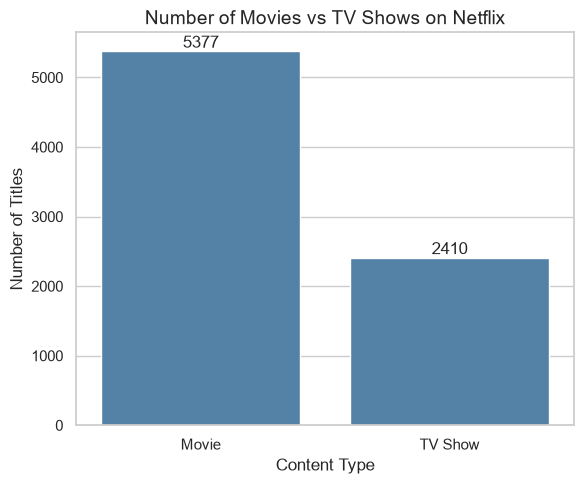

Interpretation:
- 'Movie' is the larger category with 5,377 titles (69.05% of the dataset).
- The smaller category has 2,410 titles (2.23 times fewer).


In [31]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=type_counts.index, y=type_counts.values, color="steelblue", ax=ax)

ax.set_title("Number of Movies vs TV Shows on Netflix", fontsize=14)
ax.set_xlabel("Content Type")
ax.set_ylabel("Number of Titles")
for container in ax.containers:
    ax.bar_label(container, fmt="%d")   # show exact counts on top of the bars

plt.tight_layout()
plt.show()

top_type = type_counts.idxmax()
print("Interpretation:")
print(f"- '{top_type}' is the larger category with {type_counts.max():,} titles "
      f"({type_pct[top_type]}% of the dataset).")
if len(type_counts) > 1:
    print(f"- The smaller category has {type_counts.min():,} titles "
          f"({type_counts.max() / type_counts.min():.2f} times fewer).")

### Chart 2: Number of titles by release year

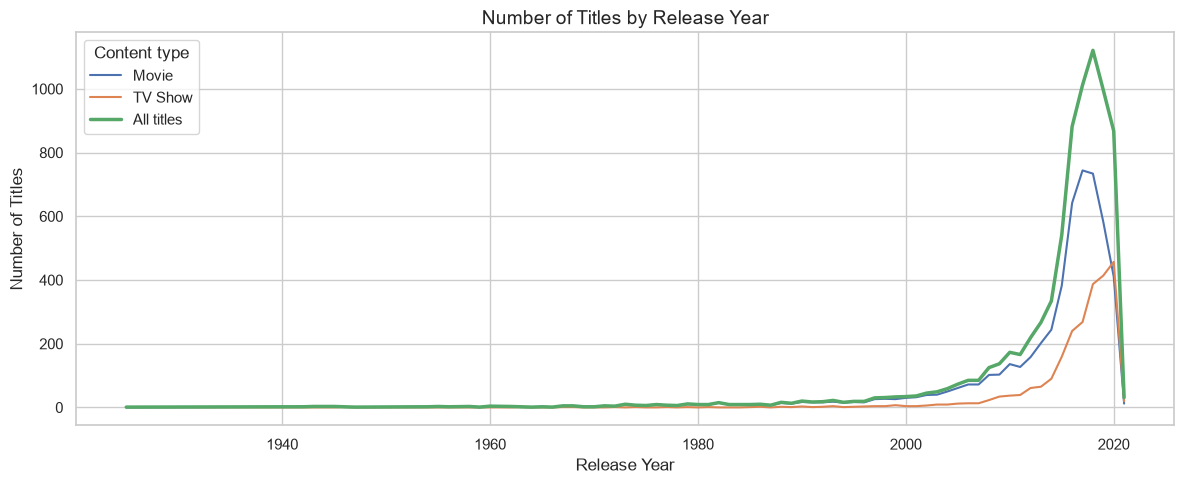

Interpretation:
- The most titles were released in 2018 (1,121 titles).
- 84.9% of all titles were released in 2010 or later.
- The earliest release year in the data is 1925.


In [32]:
fig, ax = plt.subplots(figsize=(12, 5))
for column in year_type.columns:
    ax.plot(year_type.index, year_type[column], label=column,
            linewidth=2.5 if column == "All titles" else 1.5)

ax.set_title("Number of Titles by Release Year", fontsize=14)
ax.set_xlabel("Release Year")
ax.set_ylabel("Number of Titles")
ax.legend(title="Content type")
plt.tight_layout()
plt.show()

since_2010 = (df["release_year"] >= 2010).mean() * 100
print("Interpretation:")
print(f"- The most titles were released in {peak_year} ({int(year_type['All titles'].max()):,} titles).")
print(f"- {since_2010:.1f}% of all titles were released in 2010 or later.")
print(f"- The earliest release year in the data is {int(df['release_year'].min())}.")

### Chart 3: Top 10 countries by number of titles

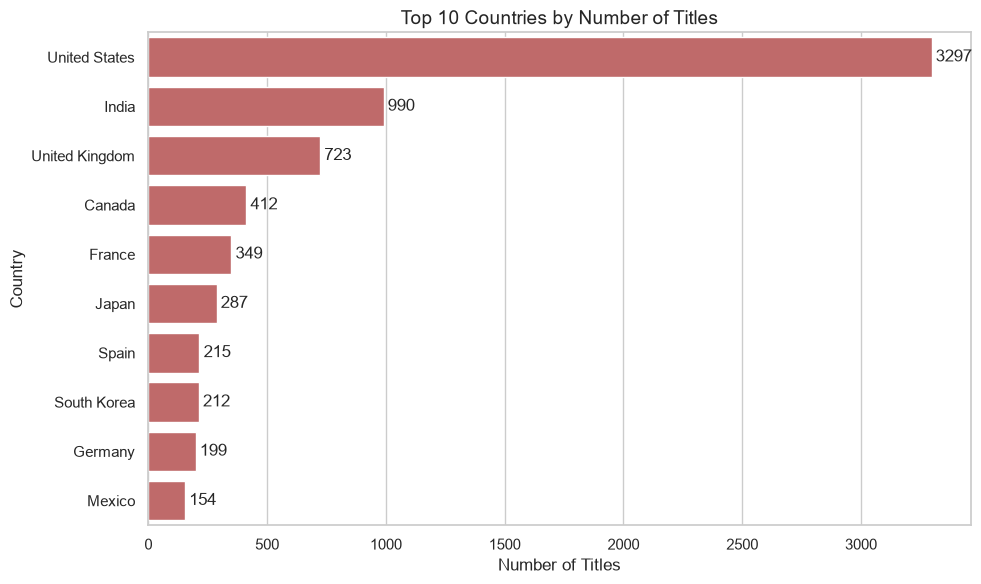

Interpretation:
- 'United States' contributes the most titles (3,297).
- The top 3 countries are: United States, India, United Kingdom.
- Titles with an unknown country (507) are not shown in this chart.
- A title with several countries is counted once for each country.


In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, orient="h", color="indianred", ax=ax)

ax.set_title("Top 10 Countries by Number of Titles", fontsize=14)
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Country")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

top3 = ", ".join(top_countries.index[:3])
print("Interpretation:")
print(f"- '{top_countries.index[0]}' contributes the most titles ({top_countries.iloc[0]:,}).")
print(f"- The top 3 countries are: {top3}.")
print(f"- Titles with an unknown country ({int((df['country'] == 'Unknown').sum()):,}) are not shown in this chart.")
print("- A title with several countries is counted once for each country.")

### Chart 4: Most common genres

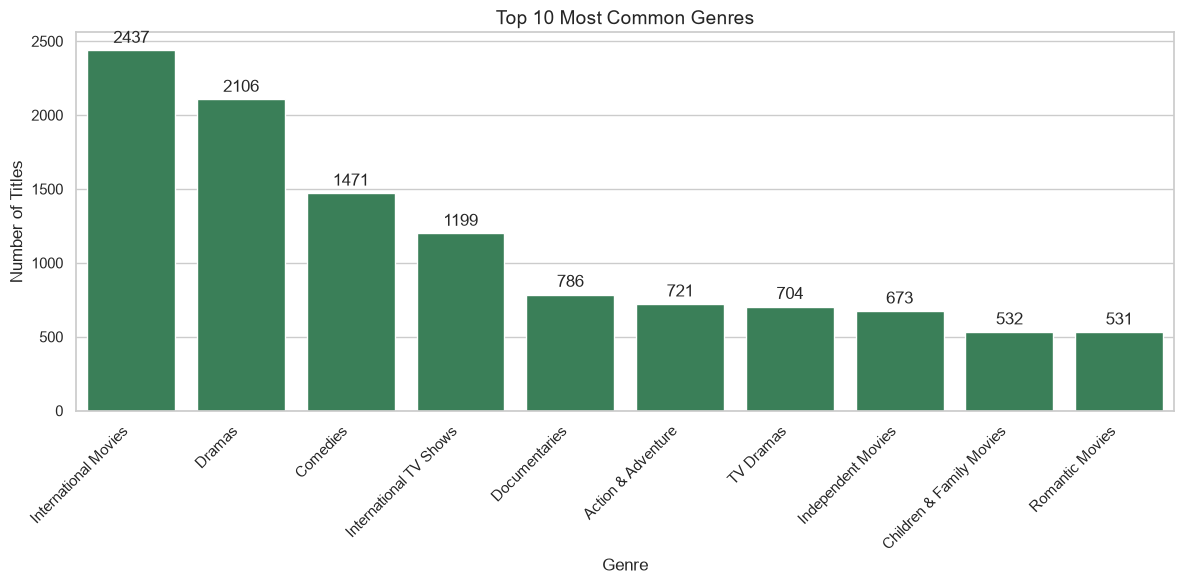

Interpretation:
- 'International Movies' is the most frequent genre label (2,437 titles).
- The top 3 genres are: International Movies, Dramas, Comedies.
- Each title can have several genres, so these counts add up to more than the number of titles.


In [34]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x=top_genres.index, y=top_genres.values, color="seagreen", ax=ax)

ax.set_title("Top 10 Most Common Genres", fontsize=14)
ax.set_xlabel("Genre")
ax.set_ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")   # rotate long genre names so they stay readable
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

print("Interpretation:")
print(f"- '{top_genres.index[0]}' is the most frequent genre label ({top_genres.iloc[0]:,} titles).")
print(f"- The top 3 genres are: {', '.join(top_genres.index[:3])}.")
print("- Each title can have several genres, so these counts add up to more than the number of titles.")

### Chart 5: Distribution of content ratings

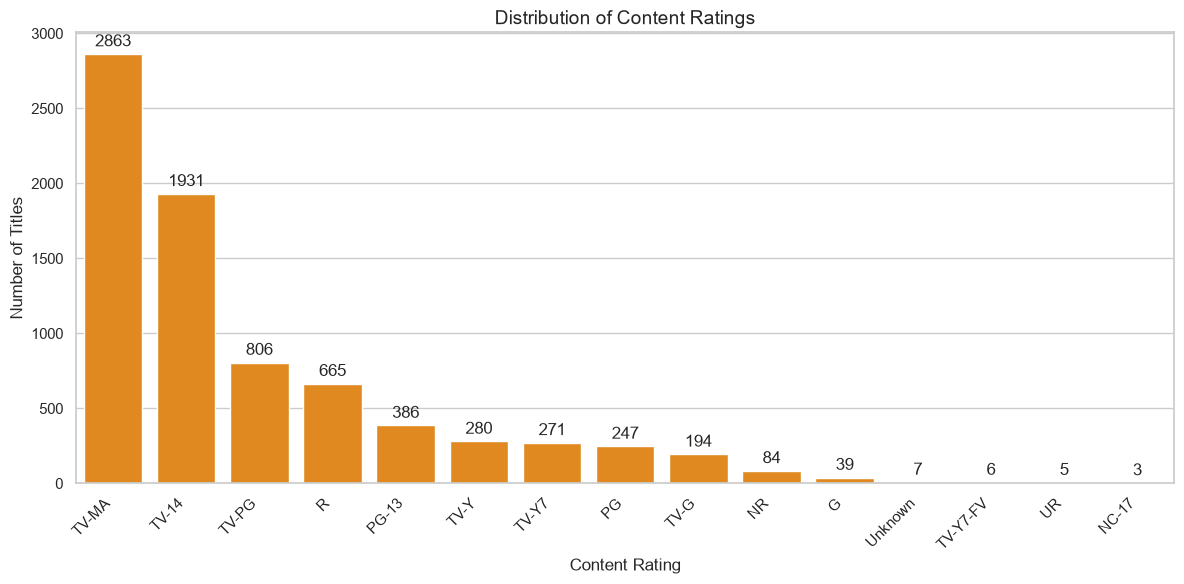

Interpretation:
- 'TV-MA' is the most common rating (2,863 titles, 36.8% of the dataset).
- The three most common ratings are: TV-MA, TV-14, TV-PG.
- 7 titles have an unknown rating (missing in the original data).


In [35]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x=rating_counts.index, y=rating_counts.values, color="darkorange", ax=ax)

ax.set_title("Distribution of Content Ratings", fontsize=14)
ax.set_xlabel("Content Rating")
ax.set_ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

top_rating = rating_counts.index[0]
print("Interpretation:")
print(f"- '{top_rating}' is the most common rating ({rating_counts.iloc[0]:,} titles, "
      f"{rating_counts.iloc[0] / len(df) * 100:.1f}% of the dataset).")
print(f"- The three most common ratings are: {', '.join(rating_counts.index[:3])}.")
if "Unknown" in rating_counts.index:
    print(f"- {rating_counts['Unknown']:,} titles have an unknown rating (missing in the original data).")

## Step 8: Key Findings
The summary below is generated from the loaded dataset, so every number comes from your data.

In [36]:
print("=" * 60)
print("KEY FINDINGS")
print("=" * 60)

print("\n1. Dataset size and structure")
print(f"   - Original data: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"   - After cleaning: {df.shape[0]:,} rows x {df.shape[1]} columns (includes helper columns)")

print("\n2. Main data quality issues")
worst = missing_table[missing_table["missing_count"] > 0].head(3)
for col, row in worst.iterrows():
    print(f"   - '{col}' has {int(row['missing_count']):,} missing values ({row['missing_percent']}%)")
print(f"   - Fully duplicate rows removed: {rows_removed}")
print(f"   - Ratings that looked like durations: {issues['rating_contains_duration']}")
print(f"   - Duration/type mismatches: {issues['duration_type_mismatch']}")

print("\n3. Movies vs TV Shows")
for t, c in type_counts.items():
    print(f"   - {t}: {c:,} ({type_pct[t]}%)")

print("\n4. Release-year trends")
print(f"   - Release years range from {int(df['release_year'].min())} to {int(df['release_year'].max())}")
print(f"   - Peak release year: {peak_year} ({int(year_type['All titles'].max()):,} titles)")
print(f"   - {since_2010:.1f}% of titles were released in 2010 or later")

print("\n5. Leading countries and genres")
print(f"   - Top countries: {', '.join(top_countries.index[:3])}")
print(f"   - Top genres   : {', '.join(top_genres.index[:3])}")

print("\n6. Most common content ratings")
print(f"   - {', '.join(rating_counts.index[:3])}")

print("\n7. Anomalies")
print(f"   - Movies with unusual length (IQR rule): {len(movie_outliers):,}")
print(f"   - Titles added before their release year: {len(added_before_release):,}")
print(f"   - Titles with unknown country: {int((df['country'] == 'Unknown').sum()):,}")

KEY FINDINGS

1. Dataset size and structure
   - Original data: 7,787 rows x 12 columns
   - After cleaning: 7,787 rows x 17 columns (includes helper columns)

2. Main data quality issues
   - 'director' has 2,389 missing values (30.68%)
   - 'cast' has 718 missing values (9.22%)
   - 'country' has 507 missing values (6.51%)
   - Fully duplicate rows removed: 0
   - Ratings that looked like durations: 0
   - Duration/type mismatches: 0

3. Movies vs TV Shows
   - Movie: 5,377 (69.05%)
   - TV Show: 2,410 (30.95%)

4. Release-year trends
   - Release years range from 1925 to 2021
   - Peak release year: 2018 (1,121 titles)
   - 84.9% of titles were released in 2010 or later

5. Leading countries and genres
   - Top countries: United States, India, United Kingdom
   - Top genres   : International Movies, Dramas, Comedies

6. Most common content ratings
   - TV-MA, TV-14, TV-PG

7. Anomalies
   - Movies with unusual length (IQR rule): 337
   - Titles added before their release year: 12
  

## Step 9: Conclusion

This EDA showed how the Netflix catalogue is structured, how much of it is incomplete, and which patterns stand out. We checked the size and data types, found missing values and inconsistent entries, cleaned them without discarding useful rows, and then answered questions about content type, release years, countries, genres and ratings. The charts and the generated findings above summarise those results using the numbers from the dataset.

Exploratory data analysis is useful because it comes **before** any modelling or reporting: it reveals data problems early, shows which questions the data can actually answer, highlights trends and unusual values, and helps us avoid drawing wrong conclusions from messy data.

**Limitations:** The dataset is a snapshot of Netflix's catalogue, not viewing activity, so it says nothing about popularity. Countries and genres are counted per label, so a title with several of them is counted several times. The "Unknown" label stands for missing information, not a real category.